## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#IMPORT LIBRARIES
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import evaluate_model, evaluate_reconstruction_metrics, plot_training_curves

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks_final/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


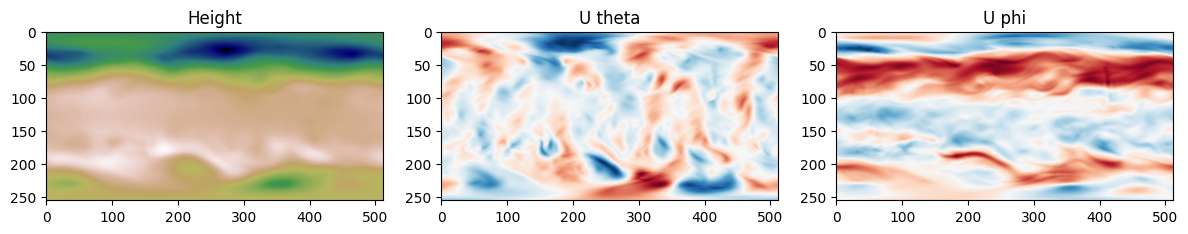

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
np.random.seed(42)  # For reproducibility
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[102 466]
 [179 214]
 [ 92 330]
 [ 14 458]
 [106  87]
 [ 71 372]
 [188  99]
 [ 20 359]
 [102 151]
 [121 130]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [102 466]): 186 of 1008 steps masked
Short broken sensor 1 (coord [179 214]): 202 of 1008 steps masked
Short broken sensor 2 (coord [ 92 330]): 186 of 1008 steps masked
Short broken sensor 3 (coord [ 14 458]): 213 of 1008 steps masked
Long broken sensor  4 (coord [106  87]): steps 308 to 661 masked
Long broken sensor  5 (coord [ 71 372]): steps 343 to 769 masked
Long broken sensor  6 (coord [188  99]): steps 413 to 491 masked
Long broken sensor  7 (coord [ 20 359]): steps 385 to 805 masked


In [6]:
from helpers import plot_data_availability
#plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

## Check -> USE ROM AS IN SHRED ROM

In [7]:
from helpers import ROM_data_preprocessing, eval_all
sensors_data, H, Utheta, Uphi = ROM_data_preprocessing(sensors_data, H, Utheta, Uphi)

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Utheta shape:		 torch.Size([1008, 131072])
Uphi shape:		 torch.Size([1008, 131072])

Sensors data shape:	 (16, 126, 10)
H shape:		 (16, 126, 131072)
Utheta shape:		 (16, 126, 131072)
Uphi shape:		 (16, 126, 131072)


In [8]:
ERRORS = []

# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.0.A) Always available sensor

In [9]:
always_available_sensors = np.arange(8,10)
print("Always available sensors:\t", always_available_sensors) 
sensors_data = sensors_data[:, :, always_available_sensors]
print("Sensors data shape:\t", sensors_data.shape)

Always available sensors:	 [8 9]
Sensors data shape:	 (16, 126, 2)


In [10]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T0A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_path.exists():
    print("Training mSHRED model...")
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )
    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred


Loading pre-trained mSHRED model...


## (T.0.B) Always available sensor (LSTM)


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="lstm", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, num_layers=ENCODER_DEPTH,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T0B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Loading pre-trained mSHRED model...


## (T.1.A): Median imputer

In [ ]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="median")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)



In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 200/200 [04:07<00:00,  1.24s/it, Train Loss=0.02939, Val Loss=0.04050, Patience=10, Best Val Loss=0.04050, LR=0.00e+00]

Training completed with best validation loss: 0.0405


## (T.1.B): Mean imputer

In [ ]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="mean")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Training mSHRED model...
Starting training...


Training: 100%|██████████| 200/200 [02:42<00:00,  1.23it/s, Train Loss=0.02873, Val Loss=0.04012, Patience=2, Best Val Loss=0.04012, LR=0.00e+00]

Training completed with best validation loss: 0.0401


## (T.1.C): Last value imputer

In [ ]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="last_value")
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T1C.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Training mSHRED model...
Starting training...


Training: 100%|██████████| 200/200 [02:44<00:00,  1.22it/s, Train Loss=0.02868, Val Loss=0.04020, Patience=12, Best Val Loss=0.04020, LR=0.00e+00]

Training completed with best validation loss: 0.0402


## (T.2.A) GRUD

In [ ]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 4, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 4, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 4, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [ ]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T2A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 200/200 [03:55<00:00,  1.18s/it, Train Loss=0.03122, Val Loss=0.04154, Patience=9, Best Val Loss=0.04153, LR=0.00e+00] 

Training completed with best validation loss: 0.0415


## (T.2.B): Attn-GRUD

In [ ]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T2B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Training mSHRED model...
Starting training...


Training: 100%|██████████| 200/200 [05:23<00:00,  1.62s/it, Train Loss=0.03132, Val Loss=0.04165, Patience=33, Best Val Loss=0.04164, LR=0.00e+00]

Training completed with best validation loss: 0.0416


## (T.3.A): Masking

In [ ]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data)
manager.add_data(Utheta, id="Velocity theta", compress=COMPRESS)
manager.add_data(Uphi, id="Velocity phi", compress=COMPRESS)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)




Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 300])

Input shape for the model: 2
Output shape for the model: 300


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3A.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
    )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [04:04<00:00,  1.02it/s, Train Loss=0.02836, Val Loss=0.03966, Patience=0, Best Val Loss=0.03965, LR=7.32e-05] 

Training completed with best validation loss: 0.0397


## (T.3.B): Masking x2 channels

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3B.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [03:23<00:00,  1.23it/s, Train Loss=0.02930, Val Loss=0.04046, Patience=0, Best Val Loss=0.04048, LR=7.32e-05] 

Training completed with best validation loss: 0.0405


## (T.3.C): Masking hidden space

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3C.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [04:06<00:00,  1.01it/s, Train Loss=0.02864, Val Loss=0.04009, Patience=1, Best Val Loss=0.04009, LR=7.32e-05]

Training completed with best validation loss: 0.0401


## (T.3.D): Masking MHSA

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3D.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [03:24<00:00,  1.22it/s, Train Loss=0.02737, Val Loss=0.03899, Patience=1, Best Val Loss=0.03901, LR=7.32e-05] 

Training completed with best validation loss: 0.0390


## (T.3.E): Masking x2 channels + MHSA

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3E.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [03:42<00:00,  1.13it/s, Train Loss=0.02912, Val Loss=0.04033, Patience=1, Best Val Loss=0.04035, LR=7.32e-05]

Training completed with best validation loss: 0.0403


## (T.3.F): Masking MHSA learned

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3F.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [09:04<00:00,  2.18s/it, Train Loss=0.03036, Val Loss=0.04065, Patience=2, Best Val Loss=0.04067, LR=7.32e-05]

Training completed with best validation loss: 0.0407


## (T.3.G): Masking x2 channels + MHSA learned

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

model_path = Path("models_saved/T3G.pth")
model_path.parent.mkdir(parents=True, exist_ok=True)
model_exists = model_path.exists()

#if not already trained, train the model and save it, otherwise load the model from disk
if not model_exists:
    print("Training mSHRED model...")

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
     )

    torch.save(mshred.state_dict(), model_path)

else:
    print("Loading pre-trained mSHRED model...")
    mshred.load_state_dict(torch.load(model_path, map_location=device))
    mshred.eval()

eval_all(manager, mshred, train_dataset, val_dataset, test_dataset, H, Utheta, Uphi)

del model_args, model_path, mshred
del model_exists
del train_dataset, val_dataset, test_dataset


Training mSHRED model...
Starting training...


Training: 100%|██████████| 250/250 [06:51<00:00,  1.64s/it, Train Loss=0.02803, Val Loss=0.03972, Patience=0, Best Val Loss=0.03974, LR=7.32e-05] 

Training completed with best validation loss: 0.0397
